In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split

PATH = "adiccion_pantalla_procesado.csv.gz"

df = pd.read_csv(PATH)
print(f"Dimensiones: {df.shape}")

Dimensiones: (691369, 16)


In [10]:
df.head(10)

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label,otros_usos_hours,prop_redes,dif_finde_hours
0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1,NaN,NaN,NaN
1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0,NaN,0.1809,NaN
2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0,NaN,NaN,2.38
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1,0.38,0.1963,2.24
4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1,4.57,0.1670,2.19
5,28.0,7.37,1.78,1.56,3.38,8.33,210.0,40.0,7.85,Male,High,No,0,0.65,0.2415,0.48
6,18.0,4.24,1.61,1.14,0.91,5.09,220.0,68.0,7.46,Other,Low,Yes,0,0.58,0.3797,3.22
7,25.0,10.79,3.92,2.48,3.61,7.20,195.0,NaN,13.45,Other,High,No,1,0.78,0.3633,2.66
8,26.0,8.42,2.57,3.41,1.90,6.64,99.0,27.0,8.35,Other,Medium,Yes,0,0.54,0.3052,-0.07
9,20.0,8.74,1.40,2.43,2.11,8.57,NaN,109.0,10.68,Other,High,NaN,1,2.80,0.1602,1.94


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 691369 entries, 0 to 691368
Data columns (total 16 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   age                      662440 non-null  float64
 1   daily_screen_time_hours  595515 non-null  float64
 2   social_media_hours       557374 non-null  float64
 3   gaming_hours             564548 non-null  float64
 4   work_study_hours         639851 non-null  float64
 5   sleep_hours              646889 non-null  float64
 6   notifications_per_day    623785 non-null  float64
 7   app_opens_per_day        610659 non-null  float64
 8   weekend_screen_time      579306 non-null  float64
 9   gender                   662335 non-null  object 
 10  stress_level             636221 non-null  object 
 11  academic_work_impact     647145 non-null  object 
 12  addicted_label           691369 non-null  int64  
 13  otros_usos_hours         421427 non-null  float64
 14  prop

In [12]:
df.isnull().sum()

,0
age,28929
daily_screen_time_hours,95854
social_media_hours,133995
gaming_hours,126821
work_study_hours,51518
sleep_hours,44480
notifications_per_day,67584
app_opens_per_day,80710
weekend_screen_time,112063
gender,29034


In [13]:
y_COL = "addicted_label"
X_COLS = [
    "age", "daily_screen_time_hours", "social_media_hours", "gaming_hours",
    "work_study_hours", "sleep_hours", "notifications_per_day",
    "app_opens_per_day", "weekend_screen_time",
    "gender", "stress_level", "academic_work_impact",
]

y = df[y_COL]
X = df[X_COLS]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print("Prevalencia Y=1 -> total:", round(y.mean(), 4),
      "| train:", round(y_train.mean(), 4),
      "| test:", round(y_test.mean(), 4))

(553095, 12) (138274, 12)
Prevalencia Y=1 -> total: 0.7094 | train: 0.7094 | test: 0.7094


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

NUM = ["age", "daily_screen_time_hours", "social_media_hours",
            "gaming_hours", "work_study_hours", "sleep_hours",
            "notifications_per_day", "app_opens_per_day", "weekend_screen_time"]
NOM = ["gender", "academic_work_impact"]
ORD = ["stress_level"]

prep_base = ColumnTransformer(
    transformers=[
        ("NUM", SimpleImputer(strategy="median"), NUM),
        ("ORD", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("enc", OrdinalEncoder(categories=[["Low", "Medium", "High"]])),
        ]), ORD),
        ("NOM", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("enc", OneHotEncoder(drop="if_binary", handle_unknown="ignore",
                                  sparse_output=False)),
        ]), NOM),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

Xt = prep_base.fit(X_train).transform(X_train)
print(Xt.shape)
print("NaN restantes:", Xt.isna().sum().sum())
print(Xt.columns.tolist())
print("stress_level únicos:", sorted(Xt["stress_level"].unique()))
print("Medianas aprendidas en train:",
      dict(zip(NUM, prep_base.named_transformers_["NUM"].statistics_)))
Xt.head(5)

(553095, 14)
NaN restantes: 0
['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time', 'stress_level', 'gender_Female', 'gender_Male', 'gender_Other', 'academic_work_impact_Yes']
stress_level únicos: [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
Medianas aprendidas en train: {'age': np.float64(27.0), 'daily_screen_time_hours': np.float64(7.77), 'social_media_hours': np.float64(2.31), 'gaming_hours': np.float64(1.33), 'work_study_hours': np.float64(2.2), 'sleep_hours': np.float64(6.8), 'notifications_per_day': np.float64(150.0), 'app_opens_per_day': np.float64(104.0), 'weekend_screen_time': np.float64(9.58)}


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,stress_level,gender_Female,gender_Male,gender_Other,academic_work_impact_Yes
563697,25.0,6.74,2.31,1.33,2.20,6.23,223.0,169.0,10.14,1.0,1.0,0.0,0.0,1.0
673485,35.0,7.77,1.37,1.00,1.35,6.30,150.0,104.0,5.67,1.0,0.0,0.0,1.0,1.0
440270,20.0,7.79,2.42,0.22,4.66,6.90,186.0,104.0,7.96,2.0,0.0,1.0,0.0,0.0
378032,18.0,3.46,1.17,0.69,2.20,5.58,142.0,140.0,5.46,1.0,0.0,1.0,0.0,1.0
446226,29.0,7.77,2.19,1.35,3.73,8.78,197.0,121.0,10.58,2.0,0.0,1.0,0.0,1.0


In [15]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, SplineTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import make_scorer, recall_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# clase positiva = 1
SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "recall_clase0": make_scorer(recall_score, pos_label=0),
    "roc_auc": "roc_auc",
    "ap": "average_precision",
}

X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train, train_size=100_000, stratify=y_train, random_state=42
)

COLS_REGLA = ["daily_screen_time_hours", "social_media_hours"]
regla = Pipeline([
    ("sel", ColumnTransformer([("m", SimpleImputer(strategy="median"), COLS_REGLA)])),
    ("tree", DecisionTreeClassifier(max_depth=2, random_state=42)),
]).fit(X_train, y_train)
print(export_text(regla.named_steps["tree"], feature_names=COLS_REGLA))

# ---- Modelo 1 ----
def agrega_interaccion(df):
    df = df.copy()
    df["pantalla_x_redes"] = df["daily_screen_time_hours"] * df["social_media_hours"]
    return df

ct_lin = ColumnTransformer(
    [("spl", Pipeline([("s", SplineTransformer(degree=3, n_knots=5)),
                       ("z", StandardScaler())]), NUM)],
    remainder=StandardScaler(),
)

pipe_lr = Pipeline([
    ("prep", prep_base),
    ("inter", FunctionTransformer(agrega_interaccion)),
    ("ct", ct_lin),
    ("clf", LogisticRegression(max_iter=1000)),
])

param_lr = {"ct__spl__s__n_knots": [4, 6], "clf__C": [0.01, 0.1, 1, 10]}
gs_lr = GridSearchCV(pipe_lr, param_lr, scoring="average_precision",
                     cv=skf, n_jobs=-1, refit=False, verbose=1)
gs_lr.fit(X_sub, y_sub)

print("Mejores hiperparámetros:", gs_lr.best_params_)
print("AP medio en CV:", round(gs_lr.best_score_, 4))
display(pd.DataFrame(gs_lr.cv_results_)[["params", "mean_test_score", "std_test_score"]]
        .sort_values("mean_test_score", ascending=False))

# Reajuste final con TODO train
modelo_lr = clone(pipe_lr).set_params(**gs_lr.best_params_).fit(X_train, y_train)

|--- daily_screen_time_hours <= 6.53
|   |--- social_media_hours <= 1.50
|   |   |--- class: 0
|   |--- social_media_hours >  1.50
|   |   |--- class: 1
|--- daily_screen_time_hours >  6.53
|   |--- daily_screen_time_hours <= 8.10
|   |   |--- class: 1
|   |--- daily_screen_time_hours >  8.10
|   |   |--- class: 1

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Mejores hiperparámetros: {'clf__C': 0.1, 'ct__spl__s__n_knots': 6}
AP medio en CV: 0.9691


,params,mean_test_score,std_test_score
3,"{'clf__C': 0.1, 'ct__spl__s__n_knots': 6}",0.969134,0.001008
5,"{'clf__C': 1, 'ct__spl__s__n_knots': 6}",0.969127,0.001000
7,"{'clf__C': 10, 'ct__spl__s__n_knots': 6}",0.969125,0.001001
1,"{'clf__C': 0.01, 'ct__spl__s__n_knots': 6}",0.969031,0.001048
4,"{'clf__C': 1, 'ct__spl__s__n_knots': 4}",0.968709,0.001074
6,"{'clf__C': 10, 'ct__spl__s__n_knots': 4}",0.968705,0.001073
2,"{'clf__C': 0.1, 'ct__spl__s__n_knots': 4}",0.968699,0.001076
0,"{'clf__C': 0.01, 'ct__spl__s__n_knots': 4}",0.968526,0.001103


In [16]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV

pipe_lgbm = Pipeline([
    ("prep", prep_base),
    ("clf", LGBMClassifier(subsample_freq=1, random_state=42, verbose=-1)),
])

param_lgbm = {
    "clf__n_estimators":      [100, 300, 500],   # cantidad de árboles
    "clf__learning_rate":     [0.03, 0.1],       # cuánto aporta cada árbol
    "clf__num_leaves":        [15, 31, 63],      # complejidad de cada árbol
    "clf__min_child_samples": [20, 100, 300],    # mínimo de personas por hoja
    "clf__subsample":         [0.7, 1.0],        # fracción de filas por árbol
    "clf__colsample_bytree":  [0.7, 1.0],        # fracción de variables por árbol
}

rs_lgbm = RandomizedSearchCV(
    pipe_lgbm, param_lgbm, n_iter=15, scoring="average_precision",
    cv=skf,
    n_jobs=1,
    refit=False, random_state=42, verbose=1,
)
rs_lgbm.fit(X_sub, y_sub)

print("Mejores hiperparámetros:", rs_lgbm.best_params_)
print("AP medio en CV:", round(rs_lgbm.best_score_, 4))
display(pd.DataFrame(rs_lgbm.cv_results_)[["params", "mean_test_score", "std_test_score"]]
        .sort_values("mean_test_score", ascending=False).head(8))

# Reajuste final con TODO train
modelo_lgbm = clone(pipe_lgbm).set_params(**rs_lgbm.best_params_).fit(X_train, y_train)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Mejores hiperparámetros: {'clf__subsample': 1.0, 'clf__num_leaves': 31, 'clf__n_estimators': 500, 'clf__min_child_samples': 300, 'clf__learning_rate': 0.1, 'clf__colsample_bytree': 1.0}
AP medio en CV: 0.9827


,params,mean_test_score,std_test_score
1,"{'clf__subsample': 1.0, 'clf__num_leaves': 31,...",0.982658,0.000629
14,"{'clf__subsample': 1.0, 'clf__num_leaves': 15,...",0.982343,0.000576
3,"{'clf__subsample': 1.0, 'clf__num_leaves': 31,...",0.982243,0.000769
12,"{'clf__subsample': 0.7, 'clf__num_leaves': 63,...",0.982023,0.000561
8,"{'clf__subsample': 1.0, 'clf__num_leaves': 15,...",0.981907,0.000703
10,"{'clf__subsample': 1.0, 'clf__num_leaves': 31,...",0.981625,0.000724
4,"{'clf__subsample': 1.0, 'clf__num_leaves': 31,...",0.981493,0.000645
6,"{'clf__subsample': 0.7, 'clf__num_leaves': 31,...",0.980815,0.000785


In [17]:
from sklearn.model_selection import cross_validate

modelos = {
    "Regla simple": regla,
    "Regresión logística": modelo_lr,
    "LightGBM": modelo_lgbm,
}

filas = []
for nombre, m in modelos.items():
    r = cross_validate(m, X_train, y_train, cv=skf, scoring=SCORING,
                       return_train_score=True, n_jobs=1)
    for met in SCORING:
        filas.append({
            "modelo": nombre, "métrica": met,
            "train": r[f"train_{met}"].mean(),
            "validación": r[f"test_{met}"].mean(),
            "desv. validación": r[f"test_{met}"].std(),
        })

cv_tab = pd.DataFrame(filas).round(4)
display(cv_tab.sort_values(["métrica", "modelo"]).reset_index(drop=True))

,modelo,métrica,train,validación,desv. validación
0,LightGBM,accuracy,0.9066,0.8999,0.0013
1,Regla simple,accuracy,0.8063,0.8062,0.0015
2,Regresión logística,accuracy,0.8419,0.8419,0.0005
3,LightGBM,ap,0.9869,0.9848,0.0003
4,Regla simple,ap,0.9201,0.9201,0.0004
5,Regresión logística,ap,0.9689,0.9689,0.0003
6,LightGBM,precision,0.9298,0.9251,0.0015
7,Regla simple,precision,0.7993,0.7992,0.0019
8,Regresión logística,precision,0.8852,0.8852,0.0011
9,LightGBM,recall,0.9392,0.9347,0.0007


In [18]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

UMBRAL = 0.5
proba = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos.items()}

filas = []
for n, p in proba.items():
    pred = (p >= UMBRAL).astype(int)
    p_tr = modelos[n].predict_proba(X_train)[:, 1]
    filas.append({
        "Modelo": n,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (clase 1)": precision_score(y_test, pred),
        "Recall (clase 1)": recall_score(y_test, pred),
        "Recall (clase 0)": recall_score(y_test, pred, pos_label=0),
        "F1 (clase 1)": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, p),
        "AP": average_precision_score(y_test, p),
        "AP en train": average_precision_score(y_train, p_tr),
    })

tabla_test = pd.DataFrame(filas).set_index("Modelo").round(4)
display(tabla_test)
print(f"Umbral = {UMBRAL} | Prevalencia Y=1 en test = {y_test.mean():.3f} "
      f"| Accuracy de 'predecir siempre 1' = {y_test.mean():.3f}")

,Accuracy,Precision (clase 1),Recall (clase 1),Recall (clase 0),F1 (clase 1),ROC-AUC,AP,AP en train
Modelo,,,,,,,,
Regla simple,0.8053,0.7984,0.9706,0.4016,0.8761,0.8667,0.9197,0.9201
Regresión logística,0.8410,0.8852,0.8914,0.7179,0.8883,0.9204,0.9684,0.9689
LightGBM,0.8982,0.9241,0.9332,0.8129,0.9286,0.9616,0.9845,0.9866


Umbral = 0.5 | Prevalencia Y=1 en test = 0.709 | Accuracy de 'predecir siempre 1' = 0.709


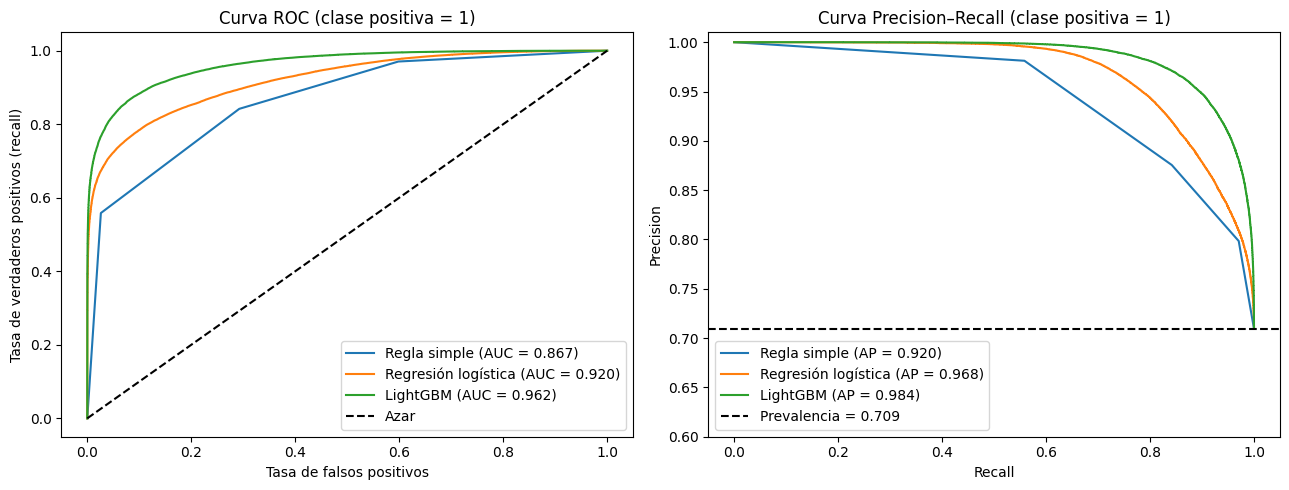

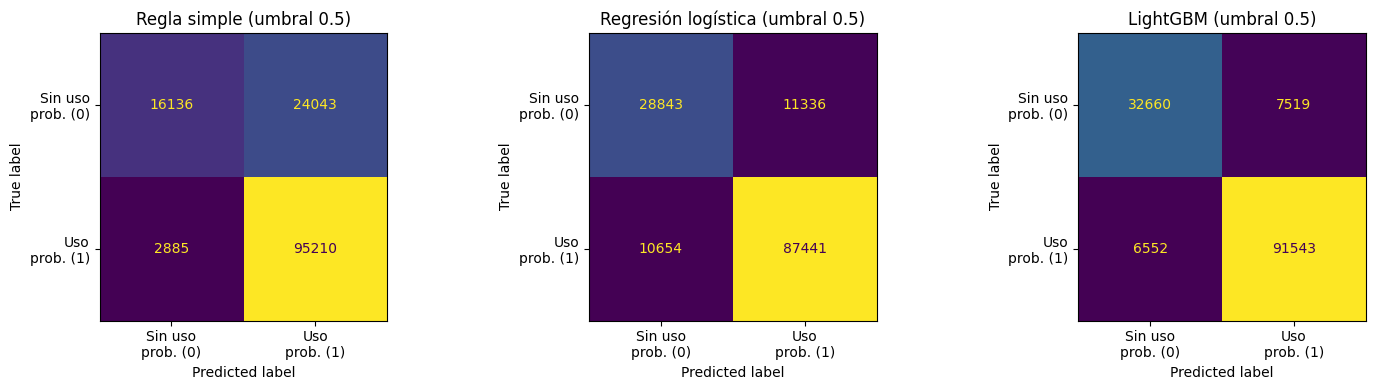

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{n} (AUC = {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rec, prec, label=f"{n} (AP = {average_precision_score(y_test, p):.3f})")

ax[0].plot([0, 1], [0, 1], "k--", label="Azar")
ax[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)",
          title="Curva ROC (clase positiva = 1)")
ax[0].legend(loc="lower right")

prev = y_test.mean()
ax[1].axhline(prev, color="k", ls="--", label=f"Prevalencia = {prev:.3f}")
ax[1].set(xlabel="Recall", ylabel="Precision", ylim=(0.6, 1.01),
          title="Curva Precision–Recall (clase positiva = 1)")
ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (n, p) in zip(ax, proba.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (p >= UMBRAL).astype(int), ax=a, colorbar=False, values_format="d",
        display_labels=["Sin uso\nprob. (0)", "Uso\nprob. (1)"])
    a.set_title(f"{n} (umbral {UMBRAL})")
plt.tight_layout(); plt.show()

In [20]:
d = X_test.copy()
d["y"] = y_test.values
for n in ["Regla simple", "Regresión logística", "LightGBM"]:
    d[n] = ((proba[n] >= UMBRAL).astype(int) != d["y"])   # True = error

d["tramo_pantalla"] = (pd.cut(d["daily_screen_time_hours"], [0, 4, 6, 8, 10, 16],
                              include_lowest=True)
                       .cat.add_categories("sin dato").fillna("sin dato"))

errores = (d.groupby("tramo_pantalla", observed=True)
             [["Regla simple", "Regresión logística", "LightGBM"]].mean().round(3))
errores["n personas"] = d.groupby("tramo_pantalla", observed=True).size()
errores["% Y=1 real"] = d.groupby("tramo_pantalla", observed=True)["y"].mean().round(3)
display(errores)

,Regla simple,Regresión logística,LightGBM,n personas,% Y=1 real
tramo_pantalla,,,,,
"(-0.001, 4.0]",0.310,0.292,0.161,12140,0.268
"(4.0, 6.0]",0.353,0.290,0.176,24450,0.356
"(6.0, 8.0]",0.296,0.235,0.160,25627,0.665
"(8.0, 10.0]",0.046,0.045,0.036,29085,0.954
"(10.0, 16.0]",0.001,0.001,0.001,27875,0.999
sin dato,0.292,0.208,0.139,19097,0.708
